In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

print("Pandas imported successfully!")
print("Pandas version:", pd.__version__)

Pandas imported successfully!
Pandas version: 3.1.0


In [3]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")

print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/Telco-Customer-Churn.csv'

In [ ]:
print("DataFrame shape:", df.shape)
 
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

DataFrame shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str   

In [ ]:
missing_values = df.isnull().sum()

print(missing_values)
print(missing_values[missing_values > 0])

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Series([], dtype: int64)


In [ ]:
print("First 10 TotalCharges values:")
print(df["TotalCharges"].head(10))

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nNumber of whitespace-only values:")
print(df["TotalCharges"].str.strip().eq("").sum())

First 10 TotalCharges values:
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

TotalCharges data type:
str

Number of whitespace-only values:
11


In [ ]:
# Select rows where TotalCharges contains only whitespace
blank_charges = df[df["TotalCharges"].str.strip().eq("")]

# Display relevant columns
print(blank_charges[["customerID", "tenure", "MonthlyCharges",
                     "TotalCharges", "Churn"]])

      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


In [ ]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

# Replace missing values with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify the changes
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())
print("Total charges for zero-tenure customers:")
print(df.loc[df["tenure"] == 0, ["tenure", "MonthlyCharges", "TotalCharges"]])

Data type: float64
Missing values: 0
Total charges for zero-tenure customers:
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           0.0
753        0           20.25           0.0
936        0           80.85           0.0
1082       0           25.75           0.0
1340       0           56.05           0.0
3331       0           19.85           0.0
3826       0           25.35           0.0
4380       0           20.00           0.0
5218       0           19.70           0.0
6670       0           73.35           0.0
6754       0           61.90           0.0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [ ]:
print("Churn distribution:")
print(df["Churn"].value_counts())

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("Churn percentage:")
print(churn_percentage.round(2))

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [ ]:
print(df[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].describe())

       SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count    7043.000000  7043.000000     7043.000000   7043.000000
mean        0.162147    32.371149       64.761692   2279.734304
std         0.368612    24.559481       30.090047   2266.794470
min         0.000000     0.000000       18.250000      0.000000
25%         0.000000     9.000000       35.500000    398.550000
50%         0.000000    29.000000       70.350000   1394.550000
75%         0.000000    55.000000       89.850000   3786.600000
max         1.000000    72.000000      118.750000   8684.800000


In [ ]:
print(df.groupby("Churn")["tenure"].mean())

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [ ]:
print(df.groupby("Churn")["tenure"].median())

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [ ]:
print("Average Monthly Charges:")
print(df.groupby("Churn")["MonthlyCharges"].mean())

print("\nMedian Monthly Charges:")
print(df.groupby("Churn")["MonthlyCharges"].median())

Average Monthly Charges:
Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

Median Monthly Charges:
Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [ ]:
print(pd.crosstab(df["Contract"], df["Churn"]))

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [ ]:
contract_churn_rate = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn_rate.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


In [ ]:
print(pd.crosstab(df["InternetService"], df["Churn"]))

Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113


In [ ]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn_rate.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 2.6 MB/s eta 0:00:04
   ------ --------------------------------- 1.6/9.5 MB 4.2 MB/s eta 0:00:02
   ----------- ---------------------------- 2.6/9.5 MB 4.6 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.5 MB 5.5 MB/s eta 0:00:01
   ------------------------ --------------- 5.8/9.5 MB 6.0 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.5 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.5 MB 6.9 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 6.7 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------------------- -------------- 1.6/2.5 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 6.9 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------- ------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


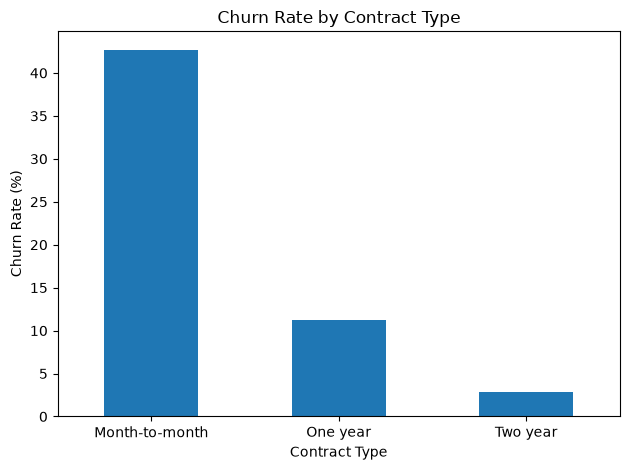

In [ ]:
%pip install matplotlib
import matplotlib.pyplot as plt
import pandas as pd

contract_churn_rate = (
    pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
)

contract_churn_rate["Yes"].plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

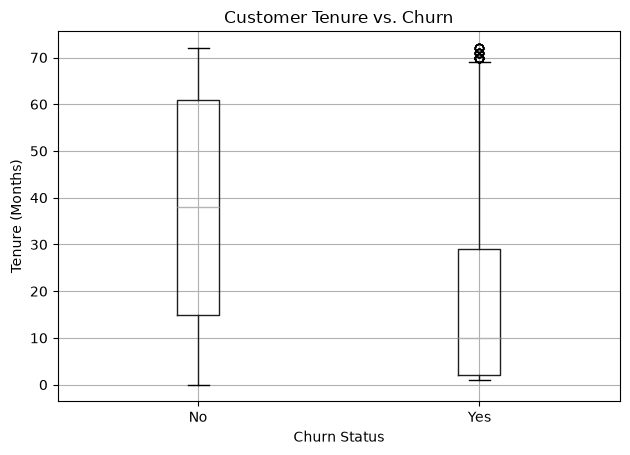

In [ ]:


df.boxplot(column="tenure", by="Churn")

plt.title("Customer Tenure vs. Churn")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

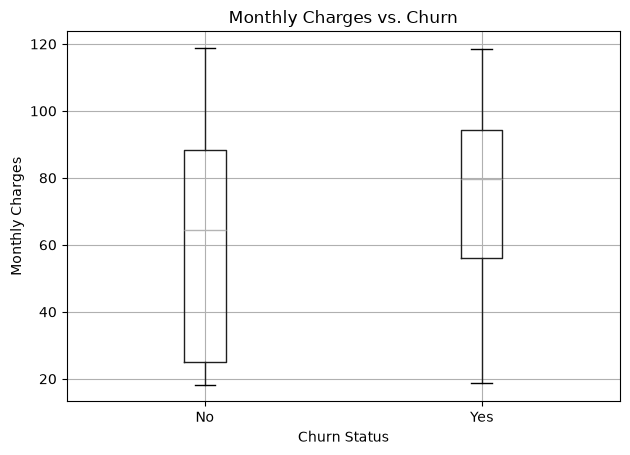

In [ ]:
df.boxplot(column="MonthlyCharges", by="Churn")

plt.title("Monthly Charges vs. Churn")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

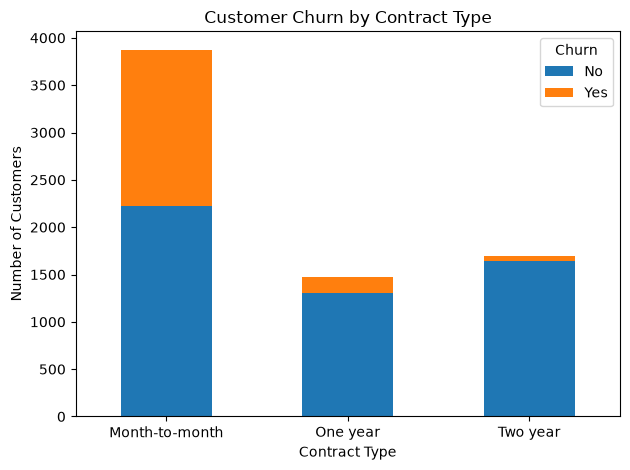

In [ ]:


contract_counts = pd.crosstab(df["Contract"], df["Churn"])

contract_counts.plot(kind="bar", stacked=True)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [ ]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


In [ ]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())


Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [ ]:
%pip install scikit-learn
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 2.6 MB/s eta 0:00:04
   ------- -------------------------------- 1.6/8.4 MB 4.3 MB/s eta 0:00:02
   ------------- -------------------------- 2.9/8.4 MB 5.1 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 6.1 MB/s eta 0:00:01
   ---------------------------- ----------- 6.0/8.4 MB 6.2 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.4 MB 6.3 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 6.1 MB/s  0:00:01
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.3/37.4 MB 9.8 MB/s eta 0:00:04
   --- ------------------------------------ 3.4/37.4 MB 9.6 MB/s eta 0:00:04
   ----- ---------------------------------- 4.7/37.4 MB 8.6 MB/s eta 0:00:04
   ------ --------------------------------- 6.3/37.4 MB 8.2 MB/s eta 0:00:04
   -------- ------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


In [ ]:
print("Numerical features:")
print(X_train.select_dtypes(include=["number"]).columns.tolist())

print("\nCategorical features:")
print(X_train.select_dtypes(include=["object", "str", "category"]).columns.tolist())

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

print("Preprocessing tools imported successfully!")


Preprocessing tools imported successfully!


In [ ]:
#Define the numerical and categorical columns
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Number of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 4

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 15


In [ ]:
#Create the ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Machine learning pipeline created successfully!")



Machine learning pipeline created successfully!


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [ ]:
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())

First 10 actual values:
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']

First 10 predicted values:
['No', 'Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No']


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 80.55%

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



Confusion Matrix:
[[926 109]
 [165 209]]


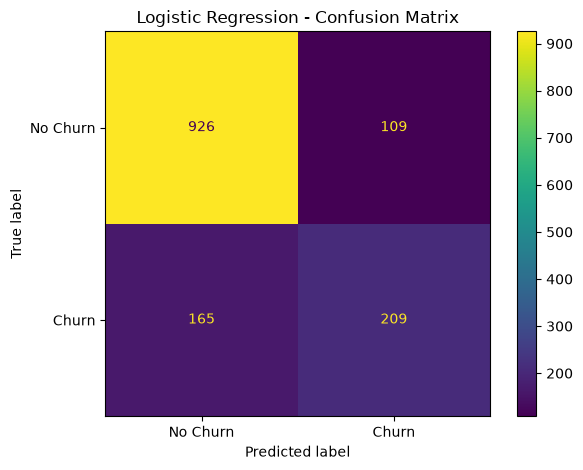

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["No", "Yes"]
)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()



In [ ]:
# Get the probability of each customer churning
y_prob = model.predict_proba(X_test)[:, 1]

# Display probabilities for the first 10 customers
print(y_prob[:10])

[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [ ]:
# Apply a threshold of 0.3
y_pred_03 = ["Yes" if prob >= 0.3 else "No" for prob in y_prob]

# Evaluate the new predictions
print("Accuracy:", round(accuracy_score(y_test, y_pred_03) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_03))

Accuracy: 74.95 %

Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.75      0.81      1035
         Yes       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the Decision Tree pipeline
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 72.11 %

Classification Report:
              precision    recall  f1-score   support

          No       0.81      0.80      0.81      1035
         Yes       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create the Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

# Evaluate the model
print(
    "Random Forest Accuracy:",
    round(accuracy_score(y_test, rf_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 78.64 %

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": (model, y_pred),
    "Decision Tree": (dt_model, dt_pred),
    "Random Forest": (rf_model, rf_pred)
}

results = []

for name, (trained_model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(
            precision_score(y_test, predictions, pos_label="Yes"), 4
        ),
        "Recall": round(
            recall_score(y_test, predictions, pos_label="Yes"), 4
        ),
        "F1-Score": round(
            f1_score(y_test, predictions, pos_label="Yes"), 4
        )
    })

results_df = pd.DataFrame(results)

print(results_df.sort_values(by="F1-Score", ascending=False))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.8055     0.6572  0.5588    0.6040
2        Random Forest    0.7864     0.6254  0.4866    0.5474
1        Decision Tree    0.7211     0.4755  0.4920    0.4836


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create a Logistic Regression model with balanced class weights
lr_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the model
lr_balanced.fit(X_train, y_train)

# Make predictions
lr_balanced_pred = lr_balanced.predict(X_test)

# Evaluate the model
print(
    "Balanced Logistic Regression Accuracy:",
    round(accuracy_score(y_test, lr_balanced_pred) * 100, 2),
    "%"
)

print("\nClassification Report:")
print(classification_report(y_test, lr_balanced_pred))

Balanced Logistic Regression Accuracy: 73.81 %

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Create the model
lr_cv_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Set up 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Explicitly define "Yes" as the positive class
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="Yes", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="Yes", zero_division=0),
    "f1": make_scorer(f1_score, pos_label="Yes", zero_division=0)
}

# Evaluate using training data only
cv_results = cross_validate(
    lr_cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring_metrics,
    n_jobs=-1
)

# Display average scores
print("Average Accuracy:", round(cv_results["test_accuracy"].mean(), 4))
print("Average Precision:", round(cv_results["test_precision"].mean(), 4))
print("Average Recall:", round(cv_results["test_recall"].mean(), 4))
print("Average F1-Score:", round(cv_results["test_f1"].mean(), 4))

Average Accuracy: 0.8021
Average Precision: 0.6529
Average Recall: 0.5431
Average F1-Score: 0.5923


In [ ]:
import numpy as np

print("Accuracy for each fold:")

for i, score in enumerate(cv_results["test_accuracy"], start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean accuracy:", round(cv_results["test_accuracy"].mean(), 4))

print(
    "Standard deviation:",
    round(cv_results["test_accuracy"].std(), 4)
)

Accuracy for each fold:
Fold 1: 0.7995
Fold 2: 0.7817
Fold 3: 0.8021
Fold 4: 0.8163
Fold 5: 0.8108

Mean accuracy: 0.8021
Standard deviation: 0.0118


In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, f1_score

# Create the F1 scorer with "Yes" as the positive class
churn_f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

# Create the pipeline
lr_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Define hyperparameter values
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

# Set up five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best C using churn F1-score
grid_search = GridSearchCV(
    estimator=lr_tuning_pipeline,
    param_grid=param_grid,
    scoring=churn_f1_scorer,
    cv=cv,
    n_jobs=-1,
    error_score="raise"
)

# Train and evaluate using training data only
grid_search.fit(X_train, y_train)

print("Best C:", grid_search.best_params_["classifier__C"])
print(
    "Best Cross-Validation F1-Score:",
    round(grid_search.best_score_, 4)
)

print("\nResults for each C value:")

for c_value, mean_score, std_score in zip(
    grid_search.cv_results_["param_classifier__C"],
    grid_search.cv_results_["mean_test_score"],
    grid_search.cv_results_["std_test_score"]
):
    print(
        f"C={c_value}: "
        f"Mean F1={mean_score:.4f}, "
        f"Standard Deviation={std_score:.4f}"
    )



Best C: 10
Best Cross-Validation F1-Score: 0.5975

Results for each C value:
C=0.01: Mean F1=0.5812, Standard Deviation=0.0269
C=0.1: Mean F1=0.5889, Standard Deviation=0.0283
C=1.0: Mean F1=0.5923, Standard Deviation=0.0299
C=10.0: Mean F1=0.5975, Standard Deviation=0.0302
C=100.0: Mean F1=0.5972, Standard Deviation=0.0288


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Get the best model selected by GridSearchCV
best_model = grid_search.best_estimator_

# Make predictions on the test set
y_pred_tuned = best_model.predict(X_test)

# Evaluate the model
print("Tuned Logistic Regression Results")
print("---------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))

print("Churn Precision:",
      round(precision_score(y_test, y_pred_tuned,
                            pos_label="Yes", zero_division=0), 4))

print("Churn Recall:",
      round(recall_score(y_test, y_pred_tuned,
                         pos_label="Yes", zero_division=0), 4))

print("Churn F1-Score:",
      round(f1_score(y_test, y_pred_tuned,
                     pos_label="Yes", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned, labels=["No", "Yes"]))



Tuned Logistic Regression Results
---------------------------------
Accuracy: 0.8048
Churn Precision: 0.6552
Churn Recall: 0.5588
Churn F1-Score: 0.6032

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409


Confusion Matrix:
[[925 110]
 [165 209]]


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Balanced Logistic Regression": lr_balanced,
    "Tuned Logistic Regression": best_model
}

results = []

for model_name, fitted_model in models.items():

    predictions = fitted_model.predict(X_test)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Churn Precision": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Churn Recall": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ),
        "Churn F1-Score": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Churn F1-Score", ascending=False
)

comparison_df.round(4)


,Model,Accuracy,Churn Precision,Churn Recall,Churn F1-Score
3,Balanced Logistic Regression,0.7381,0.5043,0.7834,0.6136
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
4,Tuned Logistic Regression,0.8048,0.6552,0.5588,0.6032
2,Random Forest,0.7864,0.6254,0.4866,0.5474
1,Decision Tree,0.7211,0.4755,0.4920,0.4836


In [ ]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Predictions from the two leading models
original_pred = model.predict(X_test)
balanced_pred = lr_balanced.predict(X_test)

# Confusion matrices
original_cm = confusion_matrix(
    y_test, original_pred, labels=["No", "Yes"]
)

balanced_cm = confusion_matrix(
    y_test, balanced_pred, labels=["No", "Yes"]
)

comparison = pd.DataFrame(
    {
        "Original Logistic Regression": [
            original_cm[0, 0],
            original_cm[0, 1],
            original_cm[1, 0],
            original_cm[1, 1]
        ],
        "Balanced Logistic Regression": [
            balanced_cm[0, 0],
            balanced_cm[0, 1],
            balanced_cm[1, 0],
            balanced_cm[1, 1]
        ]
    },
    index=[
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives"
    ]
)

print(comparison)



                 Original Logistic Regression  Balanced Logistic Regression
True Negatives                            926                           747
False Positives                           109                           288
False Negatives                           165                            81
True Positives                            209                           293


In [ ]:

import pandas as pd

# Get the fitted preprocessor and classifier
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

# Get feature names after scaling and one-hot encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = fitted_classifier.coef_[0]

# Create a DataFrame
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort features by coefficient
coefficient_df = coefficient_df.sort_values(
    by="Coefficient",
    ascending=False
)

print("Top 10 Positive Coefficients:")
print(coefficient_df.head(10).to_string(index=False))

print("\nTop 10 Negative Coefficients:")
print(
    coefficient_df.tail(10)
    .sort_values(by="Coefficient")
    .to_string(index=False)
)



Top 10 Positive Coefficients:
                            Feature  Coefficient
   cat__InternetService_Fiber optic     0.634195
       cat__Contract_Month-to-month     0.582883
                  num__TotalCharges     0.536253
           cat__StreamingMovies_Yes     0.200938
               cat__StreamingTV_Yes     0.200481
cat__PaymentMethod_Electronic check     0.197867
             cat__OnlineSecurity_No     0.156279
                cat__TechSupport_No     0.131503
             cat__MultipleLines_Yes     0.104649
                 num__SeniorCitizen     0.053449

Top 10 Negative Coefficients:
                                  Feature  Coefficient
                              num__tenure    -1.257539
                   cat__Contract_Two year    -0.776594
                 cat__InternetService_DSL    -0.648646
                      num__MonthlyCharges    -0.591863
                 cat__PaperlessBilling_No    -0.343227
     cat__StreamingTV_No internet service    -0.300104
cat__DeviceProt

In [ ]:

import numpy as np
import pandas as pd

# Use the coefficient DataFrame you created earlier
odds_ratio_df = coefficient_df.copy()

# Calculate odds ratios
odds_ratio_df["Odds_Ratio"] = np.exp(
    odds_ratio_df["Coefficient"]
)

# Display the strongest positive and negative coefficients
print("Top 10 Positive Coefficients with Odds Ratios:")
print(
    odds_ratio_df.sort_values(
        by="Coefficient", ascending=False
    ).head(10).round(4).to_string(index=False)
)

print("\nTop 10 Negative Coefficients with Odds Ratios:")
print(
    odds_ratio_df.sort_values(
        by="Coefficient", ascending=True
    ).head(10).round(4).to_string(index=False)
)



Top 10 Positive Coefficients with Odds Ratios:
                            Feature  Coefficient  Odds_Ratio
   cat__InternetService_Fiber optic       0.6342      1.8855
       cat__Contract_Month-to-month       0.5829      1.7912
                  num__TotalCharges       0.5363      1.7096
           cat__StreamingMovies_Yes       0.2009      1.2225
               cat__StreamingTV_Yes       0.2005      1.2220
cat__PaymentMethod_Electronic check       0.1979      1.2188
             cat__OnlineSecurity_No       0.1563      1.1692
                cat__TechSupport_No       0.1315      1.1405
             cat__MultipleLines_Yes       0.1046      1.1103
                 num__SeniorCitizen       0.0534      1.0549

Top 10 Negative Coefficients with Odds Ratios:
                                  Feature  Coefficient  Odds_Ratio
                              num__tenure      -1.2575      0.2844
                   cat__Contract_Two year      -0.7766      0.4600
                 cat__InternetSer

In [ ]:

import joblib
from pathlib import Path

# Create the models directory if it doesn't exist
models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline
model_path = models_dir / "balanced_logistic_regression.joblib"

joblib.dump(lr_balanced, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)



Model saved successfully!
Saved location: models\balanced_logistic_regression.joblib


In [ ]:

import joblib
from pathlib import Path

# Define the saved model path
model_path = Path("models/balanced_logistic_regression.joblib")

# Load the model
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

# Check the model type
print("\nModel details:")
print(loaded_model)



Model loaded successfully!

Model details:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceP

In [ ]:

# Select one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Predict the customer's churn status
prediction = loaded_model.predict(sample_customer)[0]

# Get the probability estimates
probabilities = loaded_model.predict_proba(sample_customer)[0]

# Find the probability associated with Churn = Yes
class_labels = loaded_model.named_steps["classifier"].classes_
churn_index = list(class_labels).index("Yes")

churn_probability = probabilities[churn_index]

print("Predicted Churn Status:", prediction)
print(f"Estimated Churn Probability: {churn_probability:.2%}")



Predicted Churn Status: No
Estimated Churn Probability: 11.77%


In [ ]:

def predict_customer_churn(customer_data, trained_model):
    """
    Predict whether a customer is likely to churn.

    Parameters:
        customer_data: A pandas DataFrame containing one customer's features.
        trained_model: A fitted preprocessing and prediction pipeline.

    Returns:
        Predicted churn status and estimated churn probability.
    """

    # Predict the churn status
    prediction = trained_model.predict(customer_data)[0]

    # Calculate class probabilities
    probabilities = trained_model.predict_proba(customer_data)[0]

    # Find the probability corresponding to Churn = Yes
    classes = list(
        trained_model.named_steps["classifier"].classes_
    )
    churn_index = classes.index("Yes")

    churn_probability = probabilities[churn_index]

    # Return the results
    return {
        "predicted_churn": prediction,
        "churn_probability": round(float(churn_probability), 4),
        "risk_level": (
            "High" if churn_probability >= 0.70
            else "Medium" if churn_probability >= 0.40
            else "Low"
        )
    }


# Test the function using one customer from X_test
sample_customer = X_test.iloc[[0]]

result = predict_customer_churn(
    sample_customer,
    loaded_model
)

print(result)



{'predicted_churn': 'No', 'churn_probability': 0.1177, 'risk_level': 'Low'}
